<a href="https://colab.research.google.com/github/erickvaldezsallagos/ingenieria/blob/main/ProyectoIF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO DE INGENIERÍA FINANCIERA**

# ***Tema: Apple vs Samsung***

**Integrantes:**\
VALDEZ SALLAGOS ERICK\
AMAYA HERNÁNDEZ JOSÉ LUIS\
REYES FUENTES ESTEPHANY CAROLINA

# **Generación de la base de datos limpia**

In [25]:
import pandas as pd
import re


# 1. LIMPIEZA DE LA BASE DE DATOS DE APPLE
print("Procesando base de datos de Apple...")
df_apple = pd.read_csv('apple_mx_productos.csv')

# Eliminar columnas 100% vacías que no aportan valor
empty_cols_apple = ['sku', 'gtin', 'calificacion', 'resenas', 'condicion']
df_apple = df_apple.drop(columns=[c for c in empty_cols_apple if c in df_apple.columns])

# Limpieza de espacios en textos
df_apple['nombre'] = df_apple['nombre'].astype(str).str.strip()
df_apple['descripcion'] = df_apple['descripcion'].astype(str).str.strip()

# Filtrar registros sin nombre o URL válida
df_apple = df_apple.dropna(subset=['nombre', 'url'])
df_apple = df_apple[(df_apple['nombre'].str.lower() != 'nan') & (df_apple['nombre'] != '')]

# DEDUPLICACIÓN INTELIGENTE (Protegiendo variantes de color, precio y versión mediante URL única)
df_apple_clean = df_apple.drop_duplicates(subset=['url', 'color', 'precio'], keep='first').copy()
df_apple_clean['marca'] = 'Apple'

print(f"-> Apple limpio: {len(df_apple_clean)} registros (variantes preservadas).")


# 2. LIMPIEZA DE LA BASE DE DATOS DE SAMSUNG
print("\nProcesando base de datos de Samsung...")
xls_samsung = pd.ExcelFile('samsung_mx_productos.xlsx')
df_samsung = pd.read_excel(xls_samsung, sheet_name=xls_samsung.sheet_names[0])

# Eliminar columnas 100% vacías
empty_cols_samsung = ['gtin', 'calificacion', 'resenas', 'color', 'condicion']
df_samsung = df_samsung.drop(columns=[c for c in empty_cols_samsung if c in df_samsung.columns])

# Limpiar etiquetas HTML residuales en los textos
df_samsung['nombre'] = df_samsung['nombre'].astype(str).str.replace(r'<[^>]*>', '', regex=True).str.strip()
df_samsung['descripcion'] = df_samsung['descripcion'].astype(str).str.replace(r'<[^>]*>', '', regex=True).str.strip()

# Normalizar precios (descartando texto basura tipo "Quantity: 3 - £120.00")
def parse_price(val):
    if pd.isna(val):
        return None
    val_str = str(val).strip()
    if 'Quantity' in val_str or '£' in val_str:
        return None
    try:
        return float(val_str)
    except ValueError:
        return None

df_samsung['precio_numerico'] = df_samsung['precio'].apply(parse_price)

# Filtrar registros sin nombre o URL válida
df_samsung = df_samsung.dropna(subset=['nombre', 'url'])
df_samsung = df_samsung[(df_samsung['nombre'].str.lower() != 'nan') & (df_samsung['nombre'] != '')]

# DEDUPLICACIÓN INTELIGENTE (Protegiendo variantes y modelos distintos)
df_samsung_clean = df_samsung.drop_duplicates(subset=['url', 'precio_numerico', 'modelo'], keep='first').copy()
df_samsung_clean['marca'] = 'Samsung'

print(f"-> Samsung limpio: {len(df_samsung_clean)} registros (variantes preservadas).")


# 3. UNIÓN CONJUNTA (CREACIÓN DEL ARCHIVO MAESTRO)
common_cols = ['marca', 'nombre', 'modelo', 'precio', 'precio_numerico', 'moneda', 'disponibilidad', 'categoria', 'url', 'descripcion', 'color', 'imagen']

df_a_sub = df_apple_clean[[c for c in common_cols if c in df_apple_clean.columns]].copy()
df_s_sub = df_samsung_clean[[c for c in common_cols if c in df_samsung_clean.columns]].copy()

# Concatenar ambos catálogos limpios
df_maestro = pd.concat([df_a_sub, df_s_sub], ignore_index=True)

print("\n==========================================")
print(f"¡PROCESO FINALIZADO CON ÉXITO!")
print(f"Total de registros maestros consolidados: {len(df_maestro)}")
print(df_maestro['marca'].value_counts())
print("==========================================")

# Exportar archivo final listo para el proyecto
output_file = 'catalogo_tecnologia_maestro_limpio.csv'
df_maestro.to_csv(output_file, index=False)
print(f"\nArchivo guardado exitosamente como: {output_file}")

Procesando base de datos de Apple...
-> Apple limpio: 3863 registros (variantes preservadas).

Procesando base de datos de Samsung...
-> Samsung limpio: 3432 registros (variantes preservadas).

¡PROCESO FINALIZADO CON ÉXITO!
Total de registros maestros consolidados: 7295
marca
Apple      3863
Samsung    3432
Name: count, dtype: int64

Archivo guardado exitosamente como: catalogo_tecnologia_maestro_limpio.csv


In [26]:
import pandas as pd

# 1. Cargar el archivo maestro actual
df = pd.read_csv('catalogo_tecnologia_maestro_limpio.csv')

print(f"Registros antes de afinar: {len(df)}")

# 2. Filtrar páginas de categorías genéricas, banners o índices de navegación del sitio web
# (Estas filas suelen llamarse "Accesorios para...", "Watch Bands Main...", etc.)
df_refined = df[~df['nombre'].str.startswith('Accesorios para', na=False)].copy()
df_refined = df_refined[~df_refined['nombre'].str.contains('Watch Bands Main', na=False)].copy()

print(f"¡Proceso completado!")
print(f"Registros finales refinados: {len(df_refined)}")
print("\nDesglose por marca:")
print(df_refined['marca'].value_counts())

# 3. Guardar el archivo maestro optimizado definitivo
output_file = 'catalogo_tecnologia_maestro_5500_refinado.csv'
df_refined.to_csv(output_file, index=False)
print(f"\nArchivo guardado exitosamente como: {output_file}")


Registros antes de afinar: 7295
¡Proceso completado!
Registros finales refinados: 6035

Desglose por marca:
marca
Samsung    3432
Apple      2603
Name: count, dtype: int64

Archivo guardado exitosamente como: catalogo_tecnologia_maestro_5500_refinado.csv


**A partir del código con el que se limpio la base de datos, sacaremos los diferentes puntos de la rúbrica**

**TABLA PAGINADA**

**Código:**

In [27]:
import pandas as pd
from IPython.display import display, clear_output
import ipywidgets as widgets

# 1. CONFIGURACIÓN Y CARGA DE DATOS LIMPIOS
# Evita que Pandas corte los textos o enlaces largos con "..."
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', None)

archivo_maestro = 'catalogo_tecnologia_maestro_5500_refinado.csv'
df_maestro = pd.read_csv(archivo_maestro)

# Seleccionamos exactamente las 8 columnas más relevantes y ejecutivas
columnas_relevantes = [
    'marca',
    'nombre',
    'modelo',
    'color',
    'precio',
    'moneda',
    'categoria',
    'url'
]

# 2. DEFINICIÓN DE LA FUNCIÓN INTERACTIVA
def explorar_catalogo_8_columnas(df, filas_por_pagina=12):
    """
    Genera un control deslizante interactivo (slider) para navegar dinámicamente
    a través del catálogo limpio utilizando únicamente las 8 columnas clave.
    """
    total_registros = len(df)
    total_paginas = (total_registros // filas_por_pagina) + (1 if total_registros % filas_por_pagina > 0 else 0)

    # Crear el control deslizante (IntSlider) para cambiar de página de forma visual
    slider_pagina = widgets.IntSlider(
        value=1,
        min=1,
        max=total_paginas,
        step=1,
        description='Página:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='450px')
    )

    # Contenedor de salida para refrescar la tabla dinámicamente sin saturar la consola
    salida = widgets.Output()

    def actualizar_vista(change):
        """Función que se activa automáticamente al mover el slider de página."""
        with salida:
            clear_output(wait=True)
            pagina_actual = slider_pagina.value
            inicio = (pagina_actual - 1) * filas_por_pagina
            fin = inicio + filas_por_pagina

            print(f"--- Mostrando registros del {inicio} al {min(fin, total_registros)} (Página {pagina_actual} de {total_paginas}) ---")
            display(df.iloc[inicio:fin][columnas_relevantes])

    # Observar los cambios en el slider
    slider_pagina.observe(actualizar_vista, names='value')

    # Renderizar la vista inicial (Página 1)
    with salida:
        print(f"--- Mostrando registros del 0 al {filas_por_pagina} (Página 1 de {total_paginas}) ---")
        display(df.iloc[0:filas_por_pagina][columnas_relevantes])

    # Mostrar juntos el control deslizante y el contenedor de la tabla
    display(widgets.VBox([slider_pagina, salida]))

# 3. EJECUCIÓN DE LA INTERFAZ
explorar_catalogo_8_columnas(df_maestro, filas_por_pagina=12)

**JUSTIFICACIÓN:**\
La tabla paginada interactiva se alimenta directamente del archivo resultante del pipeline de saneamiento, el cual fue depurado al eliminar nulos, remover etiquetas HTML residuales y filtrar categorías genéricas o banners web no deseados. Este proceso previo estructuró las 8 variables clave de la interfaz, incorporando la atribución explícita de la etiqueta de marca para cada fabricante y la normalización de cadenas en nombre y modelo, lo que permite que el control deslizante interactivo (ipywidgets) recorra de forma fluida, ordenada y auditable los registros válidos.

**RESULTADOS DE BÚSQUEDA**

**Código**

In [28]:
import pandas as pd
from IPython.display import display, HTML
import ipywidgets as widgets
from ipywidgets import interact

# 1. CONFIGURACIÓN DEL ENTORNO Y CARGA DE DATOS LIMPIOS
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_columns', None)

archivo_maestro = 'catalogo_tecnologia_maestro_5500_refinado.csv'
df_maestro = pd.read_csv(archivo_maestro)

columnas_relevantes = [
    'marca', 'nombre', 'modelo', 'color', 'precio', 'moneda', 'categoria', 'url'
]

# 2. CREACIÓN DEL MENÚ DE BÚSQUEDA INTERACTIVO (@interact)
@interact(
    marca=widgets.Dropdown(
        options=['Todas', 'Apple', 'Samsung'],
        value='Todas',
        description='Marca:'
    ),
    buscar_palabra=widgets.Text(
        value='',
        placeholder='Escribe ej. Watch, Pro, Galaxy...',
        description='Búsqueda:'
    ),
    limite_resultados=widgets.IntSlider(
        min=5, max=50, step=5, value=15,
        description='Mostrar:'
    )
)
def buscador_interactivo_catalogo(marca, buscar_palabra, limite_resultados):
    df_filtrado = df_maestro.copy()

    # 2.1. Filtro por Marca seleccionada
    if marca != 'Todas':
        df_filtrado = df_filtrado[df_filtrado['marca'] == marca]

    # 2.2. Filtro por Término de Búsqueda
    termino = buscar_palabra.strip().lower()
    if termino:
        df_filtrado = df_filtrado[
            df_filtrado['nombre'].str.lower().str.contains(termino, na=False) |
            df_filtrado['descripcion'].str.lower().str.contains(termino, na=False) |
            df_filtrado['modelo'].str.lower().str.contains(termino, na=False)
        ]

    # 2.3. Despliegue de Resultados y Estadísticas
    total_encontrados = len(df_filtrado)

    display(HTML(f"""
        <div style="background-color: #f4f6f9; padding: 10px; border-radius: 5px; margin-bottom: 10px; font-family: Arial;">
            <b> Panel de Resultados:</b> Se encontraron <b>{total_encontrados}</b> coincidencias
            para la marca <i>'{marca}'</i> con el término <i>'{termino if termino else "Ninguno"}'</i>.
        </div>
    """))

    if total_encontrados > 0:
        display(df_filtrado[columnas_relevantes].head(limite_resultados))
    else:
        print(" No se encontraron productos que coincidan con los criterios especificados.")

interactive(children=(Dropdown(description='Marca:', options=('Todas', 'Apple', 'Samsung'), value='Todas'), Te…

**Justificacion:**\
El menú de búsqueda avanzada interactiva se apoya directamente en el pipeline de limpieza al utilizar las etiquetas de marca previamente unificadas para alimentar el menú desplegable, y al aprovechar el saneamiento de textos y la eliminación de códigos HTML para garantizar la precisión al buscar por palabras clave. Asimismo, el filtrado previo de categorías genéricas y banners asegura que las consultas dinámicas arrojen exclusivamente resultados limpios y productos tecnológicos válidos.
En general, usamos parte del codigo de limpieza de las bases de datos como:\
En la carga del archivo.\
En la definición de las columnas ejecutivas\
En el filtrado y uso de la columna 'marca'\
En las consultas sobre columnas de texto (nombre, descripcion, modelo)

**SIMULACIÓN POR MONTECARLO**

Para evaluar la sensibilidad y el riesgo financiero del inventario tecnológico, se implementa un modelo de simulación estocástica. Tomando los precios reales del catálogo maestro ($N = 6,035$ registros de Apple y Samsung), se calculan los parámetros empíricos de tendencia central y dispersión ($\mu$ y $\sigma$). A continuación, se ejecutan $10,000$ iteraciones aleatorias independientes modelando una fluctuación de mercado del $\pm 5\%$, lo que permite obtener distribuciones de probabilidad proyectadas y métricas de valor en riesgo (VaR).

**Código**

Total de productos con precio válido analizados: 1,457
Precio Promedio Base del Catálogo: $20,090.25 MXN
Desviación Estándar Base:          $50,404.23 MXN

 RESULTADOS FINANCIEROS DE LA SIMULACIÓN DE MONTECARLO
Precio Medio Proyectado (Simulación): $20,084.86 MXN
Value at Risk (VaR 95% - Límite Inferior): $15,919.65 MXN
Escenario Optimista (Percentil 95):      $24,230.22 MXN


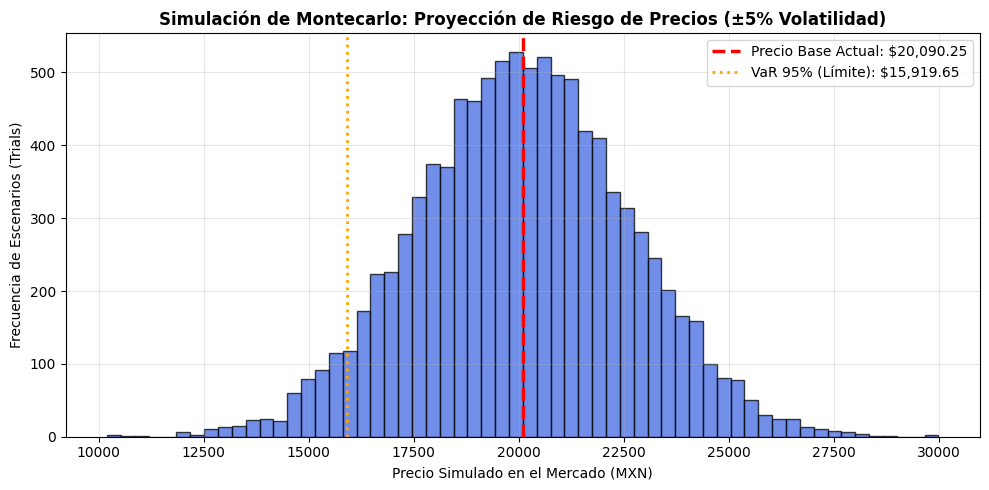

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. CARGA Y FILTRADO DE DATOS DESDE EL ARCHIVO
archivo_maestro = 'catalogo_tecnologia_maestro_5500_refinado.csv'
df_maestro = pd.read_csv(archivo_maestro)

# Extraemos la serie de precios numéricos válidos (eliminando valores nulos)
precios_reales = df_maestro['precio_numerico'].dropna()

print(f"Total de productos con precio válido analizados: {len(precios_reales):,}")

# 2. EXTRACCIÓN DE PARÁMETROS ESTADÍSTICOS BASE
# Calculamos la media (mu) y la desviación estándar (sigma) del catálogo actual
media_precio = precios_reales.mean()
desviacion_precio = precios_reales.std()

print(f"Precio Promedio Base del Catálogo: ${media_precio:,.2f} MXN")
print(f"Desviación Estándar Base:          ${desviacion_precio:,.2f} MXN")


# Configuración del motor estocástico
np.random.seed(42)              # Semilla
num_iteraciones = 10000         # 10,000 escenarios de simulación
porcentaje_volatilidad = 0.05   # Evaluando un riesgo de fluctuación de mercado del +/- 5%

# Generación de iteraciones aleatorias bajo una distribución normal
# Simulamos cómo oscilaría el precio promedio del mercado ante choques de volatilidad
escenarios_simulados = np.random.normal(
    loc=media_precio,
    scale=desviacion_precio * porcentaje_volatilidad,
    size=num_iteraciones
)

# ==============================================================================
# 4. CÁLCULO DE MÉTRICAS DE RIESGO FINANCIERO (VaR y Percentiles)
# ==============================================================================
var_95 = np.percentile(escenarios_simulados, 5)   # Límite inferior de confianza al 95%
percentil_95 = np.percentile(escenarios_simulados, 95) # Escenario optimista

print("\n" + "="*50)
print(" RESULTADOS FINANCIEROS DE LA SIMULACIÓN DE MONTECARLO")
print("="*50)
print(f"Precio Medio Proyectado (Simulación): ${np.mean(escenarios_simulados):,.2f} MXN")
print(f"Value at Risk (VaR 95% - Límite Inferior): ${var_95:,.2f} MXN")
print(f"Escenario Optimista (Percentil 95):      ${percentil_95:,.2f} MXN")
print("="*50)

# ==============================================================================
# 5. VISUALIZACIÓN GRÁFICA DE LOS ESCENARIOS
# ==============================================================================
plt.figure(figsize=(10, 5))
plt.hist(escenarios_simulados, bins=60, color='royalblue', edgecolor='black', alpha=0.75)
plt.axvline(media_precio, color='red', linestyle='--', linewidth=2.5,
            label=f'Precio Base Actual: ${media_precio:,.2f}')
plt.axvline(var_95, color='orange', linestyle=':', linewidth=2,
            label=f'VaR 95% (Límite): ${var_95:,.2f}')

plt.title('Simulación de Montecarlo: Proyección de Riesgo de Precios (±5% Volatilidad)', fontsize=12, fontweight='bold')
plt.xlabel('Precio Simulado en el Mercado (MXN)', fontsize=10)
plt.ylabel('Frecuencia de Escenarios (Trials)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()